In [1]:
import pandas as pd
df_train=pd.read_csv("D:/imdb-sentiment-analysis/data/train.csv")

print(df_train.shape)
print(df_train.head())


(39660, 2)
                                              review sentiment
0  in watching how the two brothers interact and ...  positive
1  this movie had potential the script was not ba...  negative
2  another small piece of the vast picture puzzle...  positive
3  i bought this movie hoping that it would be an...  negative
4  son in law did not do so hot in the box office...  positive


In [4]:
from sklearn.model_selection import train_test_split
X=df_train['review']
y=df_train['sentiment']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
print(X_train.shape, X_val.shape, y_train.shape, y_val.shape)

(31728,) (7932,) (31728,) (7932,)


In [17]:
from tensorflow.keras.layers import TextVectorization

text_vectorizer = TextVectorization(max_tokens=10000, output_mode="int", output_sequence_length=300)
text_vectorizer.adapt(X_train)

In [18]:
# Select the first two reviews
sample_reviews = X_train.iloc[:10].to_numpy()

# Convert text to integer sequences
sequences = text_vectorizer(sample_reviews)

# Check the output shape
print("Shape:", sequences.shape)

# Display the first 20 token IDs
print("First 20 tokens:", sequences[8][:300].numpy())

Shape: (10, 300)
First 20 tokens: [  11   15 1340 1047  351  237   16    4  864  254   19    4  706 3818
   11  706    1 1036  347   37 5807   78  137 4229   70    8  283  704
  156  961   76   12   31  218    7  178 9579 3560    3   46   22   94
    8  513    2  306  528  900 1139  612    4    1    2 8034    5  789
    3  419  195    7    1   31  119    3 2930 2089   31  243   63  161
   22  585  134    8   15  853    6   61  582  225    2   21    9   11
 1394   52  689    2 2283   15   13   66   39 2298    7   58   53   76
    4  383 7461    3    2  789    7   49    5    2   91 1080    3 5416
   10  137  108   19    2 5168    1  380  257  117    2  789    5    2
    1  515    1  104    7  563   12 5401 3851 1063  910   37    2  518
 4690    1 3137 2070    2  951   33 1379  309 1582    4 1060 3710   18
    2  626    1    1    6 1261    6   48   25   75  119    3    2 1058
    7   36  551   12   61    2   54  187   74   29 1134   16   18 1524
 1261    6 2971 6933   14  206  674    0   

In [29]:
from tensorflow.keras.layers import Embedding,LSTM,Input,Dense
from tensorflow.keras.models import Sequential

lstm_model=Sequential([
    Input(shape=(1,),dtype="string"),
    text_vectorizer,
    Embedding(len(text_vectorizer.get_vocabulary()),32,mask_zero=True),
    LSTM(32),
    Dense(1,activation="sigmoid")
])

lstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_4            │ (None, 300)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 300, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,353 (1.25 MB)

 Trainable params: 328,353 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
lstm_model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
y_train_encoded=y_train.map({"positive":1,"negative":0}).to_numpy()
y_val_encoded=y_val.map({"positive":1,"negative":0}).to_numpy()

print(y_train_encoded[:10])
print(y_val_encoded[:10])


[0 1 1 0 0 1 0 0 0 0]
[0 1 1 1 0 0 1 1 0 1]


In [36]:
import tensorflow as tf
import pandas as pd

# Verify that label encoding produced no missing values
print("Train NaNs:", pd.isna(y_train_encoded).sum())
print("Validation NaNs:", pd.isna(y_val_encoded).sum())

# Convert text into string tensors
train_text = tf.reshape(
    tf.constant(X_train.tolist(), dtype=tf.string), (-1, 1)
)

val_text = tf.reshape(
    tf.constant(X_val.tolist(), dtype=tf.string), (-1, 1)
)

# Create batched datasets
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_text, tf.constant(y_train_encoded, dtype=tf.float32))
).shuffle(10000, seed=42).batch(64).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_text, tf.constant(y_val_encoded, dtype=tf.float32))
).batch(64).prefetch(tf.data.AUTOTUNE)

print("Train batches:", train_ds.cardinality().numpy())
print("Validation batches:", val_ds.cardinality().numpy())

Train NaNs: 0
Validation NaNs: 0
Train batches: 496
Validation batches: 124


In [37]:
history = lstm_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
)

Epoch 1/3


d:\imdb-sentiment-analysis\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


496/496 ━━━━━━━━━━━━━━━━━━━━ 75s 139ms/step - accuracy: 0.7961 - loss: 0.4290 - val_accuracy: 0.8235 - val_loss: 0.4151
Epoch 2/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 73s 147ms/step - accuracy: 0.8994 - loss: 0.2575 - val_accuracy: 0.8671 - val_loss: 0.3086
Epoch 3/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 73s 147ms/step - accuracy: 0.9237 - loss: 0.2071 - val_accuracy: 0.8797 - val_loss: 0.3233


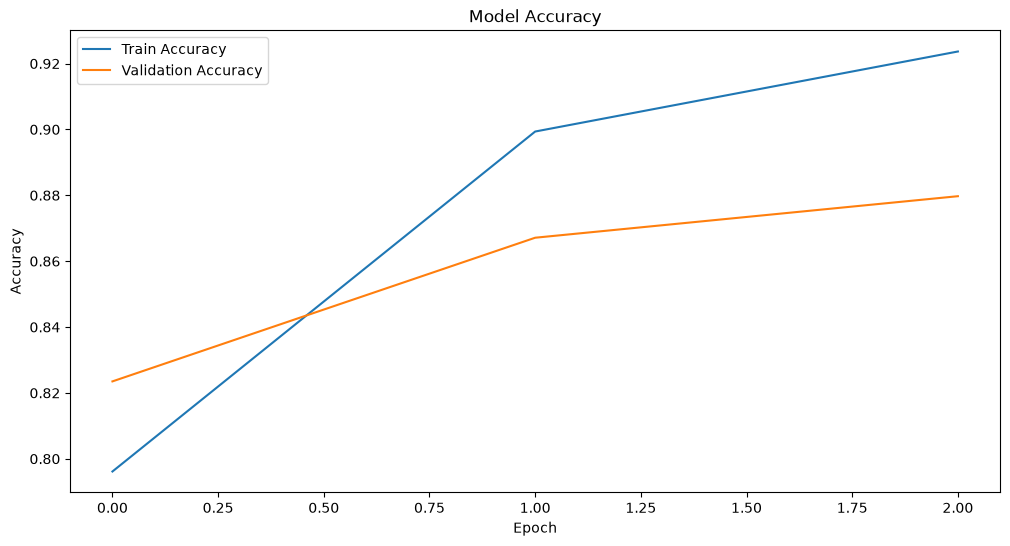

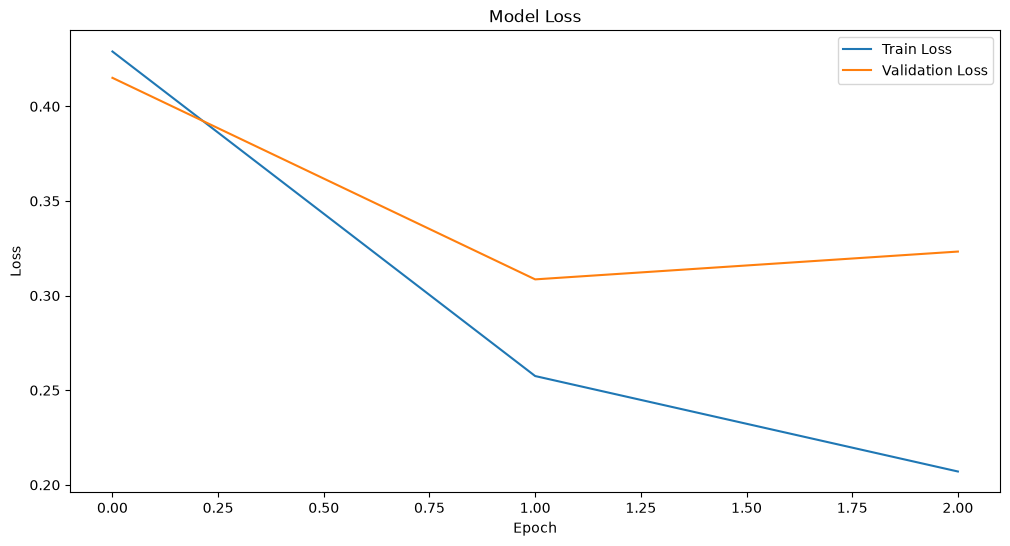

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()

plt.figure(figsize=(12,6))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model Loss')
plt.legend()
plt.show()


In [48]:
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
y_prob=lstm_model.predict(val_ds)
y_pred=(y_prob > 0.5).astype(int).ravel()

accuracy=accuracy_score(y_val_encoded, y_pred)
f1=f1_score(y_val_encoded, y_pred)
precision=precision_score(y_val_encoded, y_pred)
recall=recall_score(y_val_encoded, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")



124/124 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step
Accuracy: 0.8797
F1 Score: 0.8797
Precision: 0.8835
Recall: 0.8759


In [49]:
lstm_model.save("D:/imdb-sentiment-analysis/models/lstm_model.keras")

In [50]:
lstm_loaded=tf.keras.models.load_model("D:/imdb-sentiment-analysis/models/lstm_model.keras")
lstm_loaded.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_4            │ (None, 300)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 300, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 985,061 (3.76 MB)

 Trainable params: 328,353 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 656,708 (2.51 MB)